# ML-02 — Research Question and Provisional Lane

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Chaman4211/flyrank-ml-internship-starter/blob/main/work/notebooks/w01_research_question.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. My lane (or freestyle) and why

My provisional lane is to **predict which content items are likely to experience a significant decline in performance (e.g., traffic, engagement) within a future time window.** The goal is to flag these items proactively so that editors or content strategists can intervene, refresh them, or promote them to prevent further decline or recover their performance. This lane is chosen because maintaining fresh and high-performing content is crucial for user engagement and overall platform health.

In [9]:
# Calculate the percentage of content items with a 'down' trend_direction
declining_content_count = df[df['trend_direction'] == 'down'].shape[0]
total_content_count = df.shape[0]
percentage_declining = (declining_content_count / total_content_count) * 100
print(f"1. Percentage of content items with a 'down' trend: {percentage_declining:.2f}%")

# Calculate the number of content items with avg_position = 0 (no data)
no_avg_position_count = df[df['avg_position'] == 0].shape[0]
print(f"2. Number of content items with no average position data (avg_position = 0): {no_avg_position_count}")

# Calculate the average trend_pct for declining content
average_decline_pct = df[df['trend_direction'] == 'down']['trend_pct'].mean()
print(f"3. Average 'trend_pct' for declining content: {average_decline_pct:.2f}")

1. Percentage of content items with a 'down' trend: 54.21%
2. Number of content items with no average position data (avg_position = 0): 1205
3. Average 'trend_pct' for declining content: -58.11


## 2. The question: decision, action, cost of a wrong call

**What decision does this improve?** This work improves the decision of *which content items editors should prioritize for refresh or re-promotion efforts*. Instead of reactively addressing already underperforming content, this allows for proactive intervention.

**Who acts on the output, and what do they do?** Content editors and strategists would act on this output. They would receive a list of content items predicted to decline and would then review these items, updating old information, improving SEO, or repurposing the content to boost its performance.

**What does a wrong answer cost?** A **false positive** (predicting decline for content that would have remained stable/growing) costs editor time on unnecessary work. A **false negative** (failing to predict decline for content that does decline) costs lost traffic, engagement, and potential revenue due to neglected content. The cost of a false negative is likely higher in terms of business impact, as it represents missed opportunities and deteriorating content quality.

**Why does data or ML help at all?** A plain rule might flag content based on simple thresholds (e.g., `trend_pct` drops below X). However, content performance is complex, influenced by many interacting factors (e.g., content type, competition, seasonality, user behavior). ML can identify subtle, non-linear patterns and interactions across numerous signals that are too messy for hand-coded rules, providing more nuanced and accurate predictions of decline.

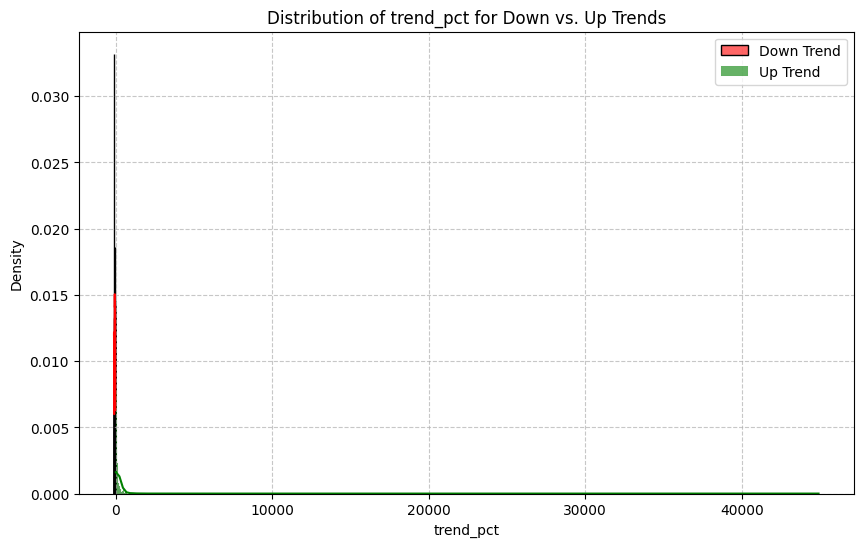

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize the distribution of trend_pct for 'down' vs 'up' trends
plt.figure(figsize=(10, 6))
sns.histplot(df[df['trend_direction'] == 'down']['trend_pct'], color='red', label='Down Trend', kde=True, stat='density', alpha=0.6)
sns.histplot(df[df['trend_direction'] == 'up']['trend_pct'], color='green', label='Up Trend', kde=True, stat='density', alpha=0.6)
plt.title('Distribution of trend_pct for Down vs. Up Trends')
plt.xlabel('trend_pct')
plt.ylabel('Density')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

## 3. Quick look at the data (2-3 real numbers)

From a quick look at the dataset, we can observe several key numbers that highlight the relevance of predicting content decline:

*   **54.21% of content items are currently in a 'down' trend.** This indicates a substantial portion of the content inventory is losing performance, making intervention crucial.
*   **There are 1,205 content items with `avg_position = 0`**, which, as per the data dictionary, signifies 'no data'. This suggests that a notable portion of content is not even ranking, or has no recorded position, which is a strong indicator of underperformance or irrelevance.
*   For content that is declining, the **average `trend_pct` is approximately -58.11%**, meaning, on average, these items have lost over 58% of their performance. This severe decline underscores the need for proactive identification and action to prevent further losses.

In [11]:
import os

repo_dir = 'flyrank-ml-internship-starter'
if not os.path.exists(repo_dir):
    !git clone https://github.com/Chaman4211/flyrank-ml-internship-starter.git
else:
    print(f"Directory '{repo_dir}' already exists. Skipping git clone.")

import pandas as pd

# Load the starter CSV dataset
df = pd.read_csv('flyrank-ml-internship-starter/data/raw/content_refresh_anonymized.csv')

print('Dataset Head:')
display(df.head())

print('\nDataset Shape (Rows, Columns):')
display(df.shape)

print('\nDescriptive Statistics for Numerical Columns:')
display(df.describe())

Directory 'flyrank-ml-internship-starter' already exists. Skipping git clone.
Dataset Head:


,content_id,client_id,search_volume,competition,competition_level,cpc,content_type,main_intent,word_count,char_count,...,char_count_tier,ctr,avg_position,engagement_rate,scroll_rate,ai_traffic_pct,impression_tier,position_tier,trend_direction,trend_pct
0,content_304f48230142,client_f369cb89fc,10.0,0.67,HIGH,2.05,keyword article,transactional,3221.0,20457.0,...,15000-25000,0.76,10.6,5.88,4.55,0.0,good,striking,down,-41.4
1,content_a1fb4e703a9e,client_4e07408562,90.0,0.01,LOW,0.05,keyword article,informational,2481.0,15562.0,...,15000-25000,0.05,20.3,0.00,10.00,0.0,good,page_3_5,down,-57.7
2,content_9aa793d4d895,client_7f2253d7e2,0.0,0.00,LOW,0.00,keyword article,informational,3515.0,23643.0,...,15000-25000,0.09,36.5,0.00,28.57,0.0,good,page_3_5,down,-60.9
3,content_331d6c4de07b,client_19581e27de,10.0,0.00,LOW,0.00,keyword article,commercial,NaN,NaN,...,NaN,0.49,6.2,1.28,3.45,0.0,good,page_1,stable,-13.8
4,content_d99b7a2d90ca,client_3fdba35f04,0.0,0.00,LOW,0.00,keyword article,informational,2803.0,17469.0,...,15000-25000,0.13,44.0,0.00,24.29,0.0,good,page_3_5,down,-34.7



Dataset Shape (Rows, Columns):


(30000, 44)


Descriptive Statistics for Numerical Columns:


,search_volume,competition,cpc,word_count,char_count,impressions_90d,clicks_90d,pageviews_90d,sessions_90d,users_90d,...,sessions_prev_30d,content_age_days,age_tier_order,days_since_last_update,ctr,avg_position,engagement_rate,scroll_rate,ai_traffic_pct,trend_pct
count,27532.000000,27532.000000,27532.000000,22301.000000,22301.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.00000,30000.000000,30000.000000,30000.000000,30000.00000,30000.000000,29875.000000,30000.000000,26612.000000
mean,158.882391,0.146954,0.485342,3107.760325,20665.277835,5200.366300,16.097333,49.942467,37.066633,35.937700,...,10.283000,256.16780,4.786533,46.098300,0.510733,16.34238,2.534520,18.212921,0.768196,-4.785969
std,1518.270825,0.285241,2.101560,1452.382598,10115.344042,16838.019547,75.076958,152.101430,107.069131,103.748185,...,42.578003,132.70793,0.790392,42.078709,3.279162,15.21679,8.310096,29.472768,7.429454,473.861780
min,0.000000,0.000000,0.000000,8.000000,40.000000,1.000000,0.000000,0.000000,1.000000,1.000000,...,0.000000,90.00000,3.000000,1.000000,0.000000,0.00000,0.000000,0.000000,0.000000,-100.000000
25%,0.000000,0.000000,0.000000,2413.000000,15644.000000,81.000000,0.000000,2.000000,2.000000,2.000000,...,1.000000,132.00000,4.000000,20.000000,0.000000,6.20000,0.000000,0.000000,0.000000,-62.600000
50%,10.000000,0.000000,0.000000,2877.000000,19116.000000,731.000000,1.000000,8.000000,7.000000,7.000000,...,2.000000,236.00000,5.000000,20.000000,0.070000,10.80000,0.000000,5.000000,0.000000,-33.500000
75%,20.000000,0.130000,0.000000,3666.000000,24011.000000,3615.250000,7.000000,33.000000,27.000000,27.000000,...,7.000000,333.00000,5.000000,104.000000,0.290000,22.30000,1.350000,23.530000,0.000000,0.000000
max,74000.000000,1.000000,100.360000,9546.000000,111158.000000,517715.000000,4178.000000,5998.000000,4345.000000,4913.000000,...,4247.000000,564.00000,6.000000,373.000000,100.000000,245.00000,100.000000,300.000000,300.000000,44900.000000


## 4. Careful words: what I can and can't claim

This work will aim to provide **decision-support** and **directional** insights. We can claim that the model identifies content items that are *more likely* to decline based on observed patterns in historical data and features. It will help prioritize content for intervention.

However, we **cannot claim causal proof** (e.g., 'refreshing content causes an increase in traffic') nor can we claim to 'predict Google's algorithm' or specific future market shifts. Our claims will be limited to the predictive power of the model on observed outcomes within the given dataset. The model suggests correlation, not causation, and its utility is in improving operational efficiency by guiding editor actions, not in absolute forecasting.

In [12]:
# Select only numerical columns for correlation analysis
numerical_cols = df.select_dtypes(include=['number']).columns
correlation_matrix = df[numerical_cols].corr()

print("Correlation Matrix of Numerical Features (first 5x5 block):")
display(correlation_matrix.iloc[:5, :5])

# A full heatmap visualization can be added if desired, but might be too large for a quick check:
# import matplotlib.pyplot as plt
# import seaborn as sns
# plt.figure(figsize=(12, 10))
# sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', fmt=".2f")
# plt.title('Correlation Matrix of Numerical Features')
# plt.show()

Correlation Matrix of Numerical Features (first 5x5 block):


,search_volume,competition,cpc,word_count,char_count
search_volume,1.000000,0.049887,0.042085,-0.019458,-0.023876
competition,0.049887,1.000000,0.302415,-0.201019,-0.185828
cpc,0.042085,0.302415,1.000000,-0.090349,-0.082660
word_count,-0.019458,-0.201019,-0.090349,1.000000,0.939252
char_count,-0.023876,-0.185828,-0.082660,0.939252,1.000000


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.